# RetailEdge open-vocabulary inspection: results

This notebook reads finished outputs under `results/` and nothing else. It loads no model and opens no dataset file.

If `results/test` exists it reports the one scored test run. Otherwise it reports `results/dry_run` (3 val images) and every figure title says **DRY RUN**: those numbers are a rehearsal, not a result.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

ROOT = Path.cwd() if (Path.cwd() / 'results').exists() else Path.cwd().parent
TEST = ROOT / 'results' / 'test'
RUN = TEST if TEST.exists() else ROOT / 'results' / 'dry_run'
TAG = '' if RUN == TEST else 'DRY RUN: '
CATEGORIES = ['cereal_box', 'damaged_cereal_box', 'misaligned_label']
read = lambda name: pd.read_csv(RUN / name)
print('Reading', RUN.relative_to(ROOT).as_posix(), '(the scored test run)' if not TAG else '(a rehearsal on 3 val images, not a result)')
display(Markdown((RUN / 'results_table.md').read_text(encoding='utf-8')))

Reading results/test (the scored test run)


# Results table (numbers only)

- "Held out" means the boxes and labels are newly rendered, while the backgrounds and real distractors are public Open Images photos with possible pretraining overlap, and rendered boxes differ in style from the real photo objects.
- The rendered cereal boxes print "Cereal" and the look-alikes print their own product names, so the models may partly read the text.

Headline setup: {'cereal_box': 'cereal carton', 'damaged_cereal_box': 'damaged cereal box', 'misaligned_label': 'crooked sticker'}, threshold 0.35, verifier margin 0.0.

- cereal_box: when it flags one, it is right 99% of the time (96 of 97), and it finds 99% of the real ones (96 of 97). F1 0.99.
- damaged_cereal_box: when it flags one, it is right 46% of the time (11 of 24), and it finds 28% of the real ones (11 of 39). F1 0.35.
- misaligned_label: when it flags one, it is right 0% of the time (0 of 20), and it finds 0% of the real ones (0 of 38). F1 0.00.
- Macro F1 0.446 with the verifier, 0.462 without.
- damaged_cereal_box on an intact cereal box, verifier off: 56 of 58 hit (56 boxes).
- damaged_cereal_box on an intact cereal box, verifier on: 13 of 58 hit (13 boxes).
- misaligned_label on a straight label, verifier off: 0 of 38 hit (0 boxes).
- misaligned_label on a straight label, verifier on: 0 of 38 hit (0 boxes).


## 1. Headline
The frozen wording per category with the verifier on. Precision and recall carry Wilson 95% intervals.

,category,precision,recall,f1,miou,tp,fp,fn
0,cereal_box,0.9897,0.9897,0.9897,0.9550,96.0,1.0,1.0
1,damaged_cereal_box,0.4583,0.2821,0.3492,0.9531,11.0,13.0,28.0
2,misaligned_label,0.0000,0.0000,0.0000,NaN,0.0,20.0,38.0
3,macro,NaN,NaN,0.4463,NaN,NaN,NaN,NaN


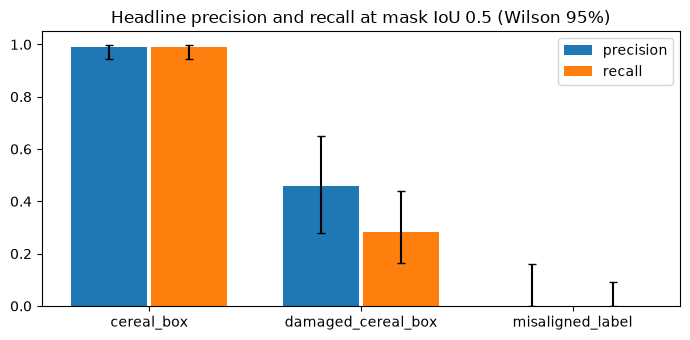

,n_truth,n_predictions,n_images,groups,miou,miou_n
category,,,,,,
cereal_box,97,97,30,4,0.9550,96
damaged_cereal_box,39,24,30,4,0.9531,11
misaligned_label,38,20,30,8,NaN,0


In [2]:
headline = read('headline.csv')
display(headline)
sens = read('sensitivity.csv')
head = sens[(sens.headline) & (sens.verifier == 'on')].set_index('category').loc[CATEGORIES]
fig, ax = plt.subplots(figsize=(7, 3.5))
for i, metric in enumerate(['precision', 'recall']):
    err = [head[metric] - head[metric + '_lo'], head[metric + '_hi'] - head[metric]]
    ax.bar([x + (i - 0.5) * 0.38 for x in range(len(head))], head[metric], 0.36, yerr=err, capsize=3, label=metric)
ax.set_xticks(range(len(head)), head.index); ax.set_ylim(0, 1.05); ax.legend()
ax.set_title(TAG + 'Headline precision and recall at mask IoU 0.5 (Wilson 95%)'); plt.tight_layout(); plt.show()
display(head[['n_truth', 'n_predictions', 'n_images', 'groups', 'miou', 'miou_n']])

## 2. Wording sensitivity
Every wording was fixed before any result, and all of them are reported. The spread is the largest minus the smallest F1 across the single wordings of a category.

,category,setup,headline,precision,recall,f1,f1_lo,f1_hi,miou,n_truth,f1_spread_across_wordings
0,cereal_box,cereal box,False,0.7823,1.0000,0.8778,0.8498,0.9106,0.9538,97,0.1939
2,cereal_box,box of cereal,False,0.6875,0.6804,0.6839,0.5978,0.7614,0.9557,97,0.1939
4,cereal_box,cereal carton,True,0.7698,1.0000,0.8700,0.8393,0.9005,0.9538,97,0.1939
6,cereal_box,ensemble,False,0.7638,1.0000,0.8661,0.8381,0.8957,0.9537,97,0.1939
8,damaged_cereal_box,damaged cereal box,True,0.3277,1.0000,0.4937,0.4079,0.5783,0.9547,39,0.0385
10,damaged_cereal_box,dented cereal box,False,0.3113,0.8462,0.4552,0.3464,0.5562,0.9539,39,0.0385
12,damaged_cereal_box,crushed cereal box,False,0.3223,1.0000,0.4875,0.3999,0.5696,0.9547,39,0.0385
14,damaged_cereal_box,ensemble,False,0.3223,1.0000,0.4875,0.4000,0.5699,0.9547,39,0.0385
16,misaligned_label,misaligned label,False,0.0000,0.0000,0.0000,0.0000,0.0000,NaN,38,0.0215
18,misaligned_label,crooked label,False,0.0000,0.0000,0.0000,0.0000,0.0000,NaN,38,0.0215


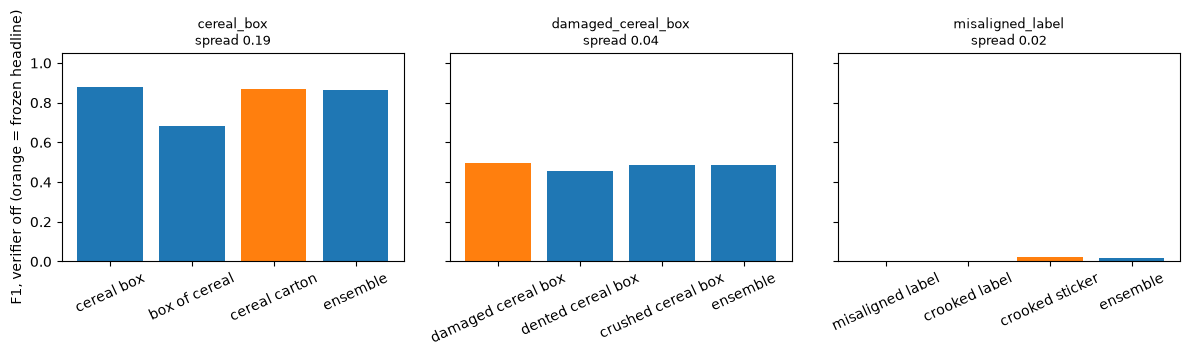

In [3]:
off = sens[sens.verifier == 'off']
display(off[['category', 'setup', 'headline', 'precision', 'recall', 'f1', 'f1_lo', 'f1_hi', 'miou', 'n_truth', 'f1_spread_across_wordings']])
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for ax, c in zip(axes, CATEGORIES):
    rows = off[off.category == c]
    ax.bar(rows.setup, rows.f1, color=['tab:orange' if h else 'tab:blue' for h in rows.headline])
    ax.set_title(TAG + f'{c}\nspread {rows.f1_spread_across_wordings.iloc[0]:.2f}', fontsize=9); ax.set_ylim(0, 1.05)
    ax.tick_params(axis='x', labelrotation=25)
axes[0].set_ylabel('F1, verifier off (orange = frozen headline)'); plt.tight_layout(); plt.show()

## 3. Verifier off versus on
The CLIP check, at the frozen temperature and margin, on the headline wording.

precision        recall            f1       
verifier                 off     on    off     on    off     on
category                                                       
cereal_box             0.770  0.990  1.000  0.990  0.870  0.990
damaged_cereal_box     0.328  0.458  1.000  0.282  0.494  0.349
misaligned_label       0.018  0.000  0.026  0.000  0.022  0.000

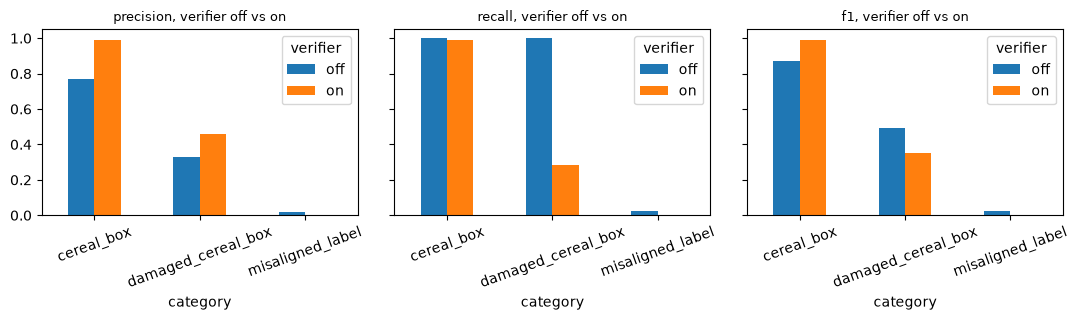

In [4]:
pair = sens[sens.headline].pivot(index='category', columns='verifier', values=['precision', 'recall', 'f1']).loc[CATEGORIES]
display(pair.round(3))
fig, axes = plt.subplots(1, 3, figsize=(11, 3.3), sharey=True)
for ax, metric in zip(axes, ['precision', 'recall', 'f1']):
    pair[metric][['off', 'on']].plot.bar(ax=ax, rot=20); ax.set_title(TAG + metric + ', verifier off vs on', fontsize=9); ax.set_ylim(0, 1.05)
plt.tight_layout(); plt.show()

## 4. Hallucination: rate and examples
**Absent-attribute rate**: the share of intact boxes (or straight labels) hit by at least one `damaged_cereal_box` (or `misaligned_label`) box above the frozen threshold. Below it, the most confident false positives, with the score each word of the prompt earned.

,category,negative_kind,verifier,negatives_hit,negatives,rate,rate_lo,rate_hi,boxes
0,damaged_cereal_box,intact_cereal_box,off,56,58,0.9655,0.8827,0.9905,56
1,damaged_cereal_box,intact_cereal_box,on,13,58,0.2241,0.1359,0.3466,13
2,misaligned_label,straight_label,off,0,38,0.0000,0.0000,0.0918,0
3,misaligned_label,straight_label,on,0,38,0.0000,0.0000,0.0918,0


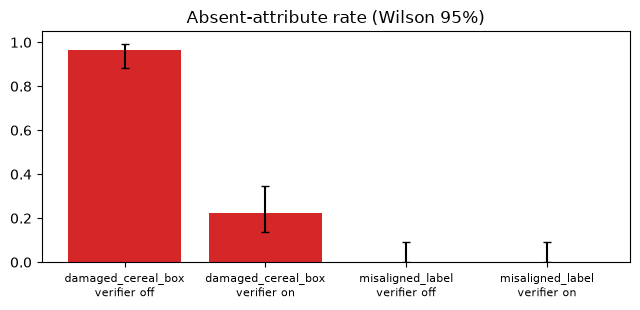

,image_id,category,wording,score,box,fp_type,word_scores,verifier_margin
0,s_test_0009,damaged_cereal_box,crushed cereal box,0.7359,"[329.7, 356.0, 538.2, 643.8]",attribute,"{""crushed"": 0.15, ""cereal"": 0.733, ""box"": 0.736}",0.1952
1,s_test_0009,damaged_cereal_box,damaged cereal box,0.7313,"[329.6, 355.9, 538.4, 643.9]",attribute,"{""damaged"": 0.123, ""cereal"": 0.731, ""box"": 0.729}",0.1952
2,s_test_0002,damaged_cereal_box,crushed cereal box,0.7205,"[744.8, 499.4, 927.1, 750.1]",attribute,"{""crushed"": 0.117, ""cereal"": 0.721, ""box"": 0.72}",0.1373
3,s_test_0002,damaged_cereal_box,damaged cereal box,0.7190,"[744.6, 499.2, 927.2, 750.1]",attribute,"{""damaged"": 0.049, ""cereal"": 0.717, ""box"": 0.719}",0.1373
4,s_test_0011,damaged_cereal_box,crushed cereal box,0.7022,"[108.4, 230.6, 286.8, 469.7]",attribute,"{""crushed"": 0.212, ""cereal"": 0.702, ""box"": 0.698}",0.2928
5,s_test_0011,damaged_cereal_box,damaged cereal box,0.6897,"[108.2, 230.3, 287.1, 469.7]",attribute,"{""damaged"": 0.348, ""cereal"": 0.69, ""box"": 0.681}",0.3036
6,s_test_0026,damaged_cereal_box,crushed cereal box,0.6719,"[321.1, 303.0, 506.7, 559.0]",attribute,"{""crushed"": 0.118, ""cereal"": 0.672, ""box"": 0.667}",0.1445
7,s_test_0019,damaged_cereal_box,crushed cereal box,0.6593,"[325.0, 704.9, 533.3, 991.3]",attribute,"{""crushed"": 0.127, ""cereal"": 0.657, ""box"": 0.659}",0.0450
8,s_test_0026,damaged_cereal_box,damaged cereal box,0.6556,"[320.9, 302.9, 506.9, 559.0]",attribute,"{""damaged"": 0.056, ""cereal"": 0.656, ""box"": 0.65}",0.1445
9,s_test_0019,damaged_cereal_box,damaged cereal box,0.6405,"[324.9, 704.8, 533.5, 991.3]",attribute,"{""damaged"": 0.059, ""cereal"": 0.641, ""box"": 0.639}",0.0450


**Boxes on a negative before the verifier:** 56 (13 kept by it)

,image_id,category,wording,score,box,word_scores,verifier_margin,kept_by_verifier
0,s_test_0008,damaged_cereal_box,damaged cereal box,0.7694,"[343.1, 416.8, 537.2, 685.6]","{""damaged"": 0.056, ""cereal"": 0.769, ""box"": 0.761}",-0.5223,False
1,s_test_0009,damaged_cereal_box,damaged cereal box,0.7313,"[329.6, 355.9, 538.4, 643.9]","{""damaged"": 0.123, ""cereal"": 0.731, ""box"": 0.729}",0.1952,True
2,s_test_0002,damaged_cereal_box,damaged cereal box,0.7232,"[499.9, 266.6, 696.1, 540.9]","{""damaged"": 0.052, ""cereal"": 0.72, ""box"": 0.723}",-0.1615,False
3,s_test_0002,damaged_cereal_box,damaged cereal box,0.7190,"[744.6, 499.2, 927.2, 750.1]","{""damaged"": 0.049, ""cereal"": 0.717, ""box"": 0.719}",0.1373,True
4,s_test_0026,damaged_cereal_box,damaged cereal box,0.7097,"[728.5, 232.2, 920.2, 510.3]","{""damaged"": 0.058, ""cereal"": 0.701, ""box"": 0.71}",-0.3432,False
5,s_test_0015,damaged_cereal_box,damaged cereal box,0.7056,"[842.3, 335.2, 996.9, 573.6]","{""damaged"": 0.085, ""cereal"": 0.702, ""box"": 0.706}",-0.2502,False
6,s_test_0002,damaged_cereal_box,damaged cereal box,0.6996,"[267.9, 254.3, 453.3, 526.7]","{""damaged"": 0.05, ""cereal"": 0.691, ""box"": 0.7}",-0.3944,False
7,s_test_0015,damaged_cereal_box,damaged cereal box,0.6956,"[159.6, 548.8, 305.1, 761.3]","{""damaged"": 0.084, ""cereal"": 0.691, ""box"": 0.696}",-0.5395,False


In [5]:
rates = read('hallucination_rates.csv')
display(rates)
fig, ax = plt.subplots(figsize=(6.5, 3.2))
labels = rates.category + '\nverifier ' + rates.verifier
ax.bar(labels, rates.rate, yerr=[rates.rate - rates.rate_lo, rates.rate_hi - rates.rate], capsize=3, color='tab:red')
ax.set_ylim(0, 1.05); ax.set_title(TAG + 'Absent-attribute rate (Wilson 95%)'); ax.tick_params(axis='x', labelsize=8)
plt.tight_layout(); plt.show()
display(read('hallucination.csv'))
candidates = read('hallucination_candidates.csv')
display(Markdown(f'**Boxes on a negative before the verifier:** {len(candidates)} ({int(candidates.kept_by_verifier.sum())} kept by it)'))
display(candidates.head(8))

101 failure overlays saved; showing up to 3


`s_test_0000__damaged_cereal_box__miss_0.png`

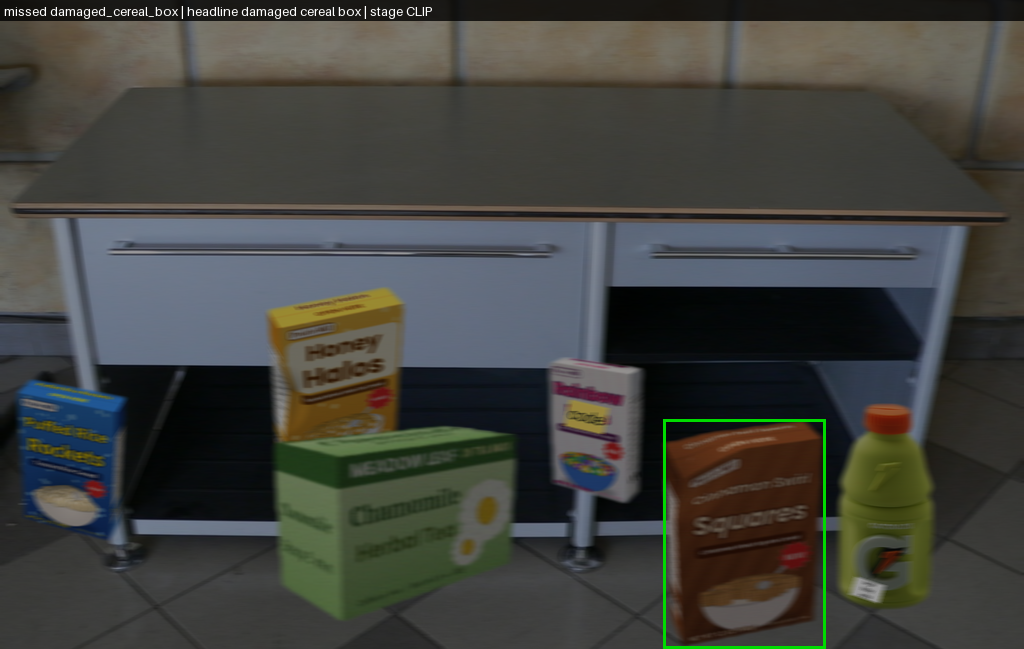

`s_test_0000__damaged_cereal_box__miss_1.png`

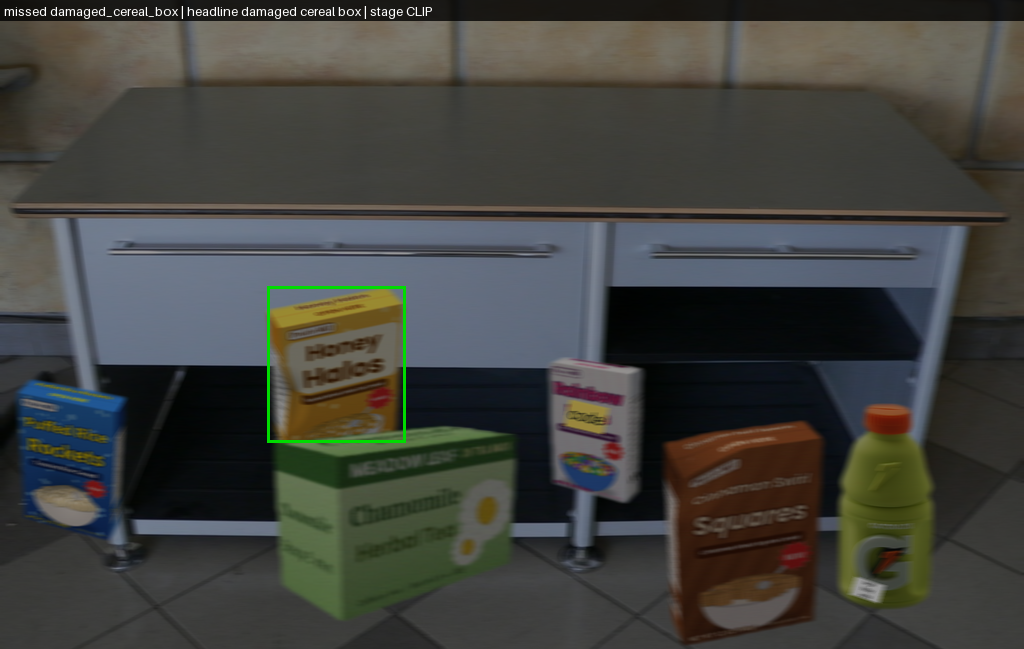

`s_test_0000__misaligned_label__fp_0.png`

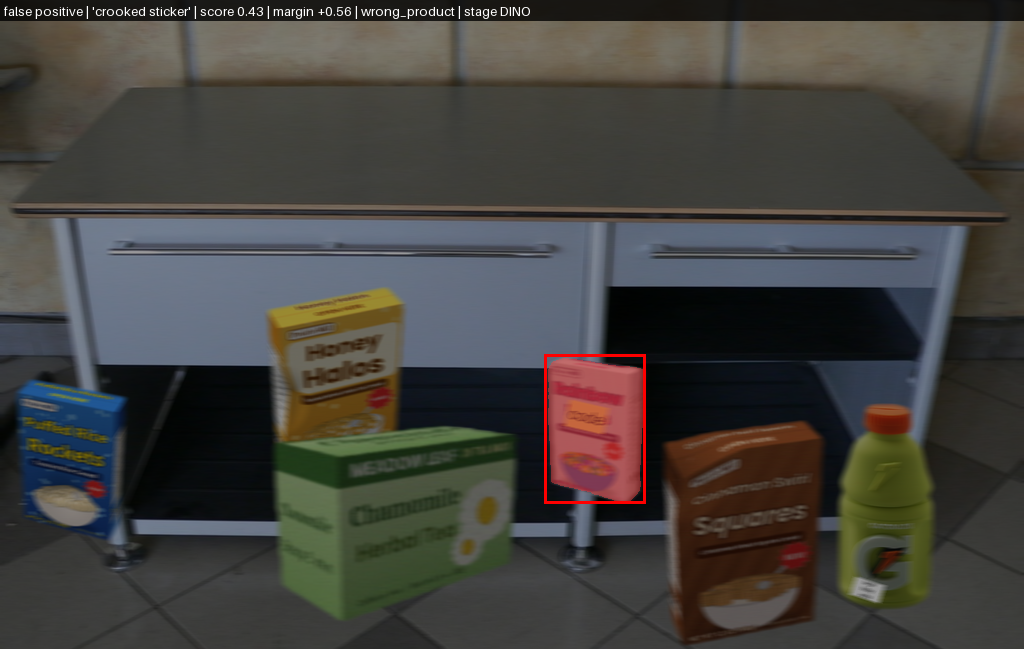

In [6]:
overlays = sorted((RUN / 'failures').glob('*.png'))
print(TAG + f'{len(overlays)} failure overlays saved; showing up to 3')
for path in overlays[:3]:
    display(Markdown('`' + path.name + '`')); display(Image(filename=str(path), width=520))

## 5. Where failures start
A miss or a false positive is blamed on the stage where it started. `verifier_also_failed` counts false positives the check let through, and `fp_caught_by_verifier` counts the ones it stopped. Oracle-box mIoU is SAM given the true box, which isolates SAM from Grounding DINO.

,miss_DINO,miss_SAM,miss_CLIP,miss_other,fp_DINO,fp_SAM,verifier_also_failed,fp_caught_by_verifier,oracle_box_sam_miou,oracle_n,pipeline_miou
category,,,,,,,,,,,
cereal_box,0,0,1,0,1,0,1,28,0.9541,97,0.955005
damaged_cereal_box,0,0,28,0,13,0,13,67,0.9551,39,0.953100
misaligned_label,37,0,1,0,20,0,20,34,0.9246,38,NaN


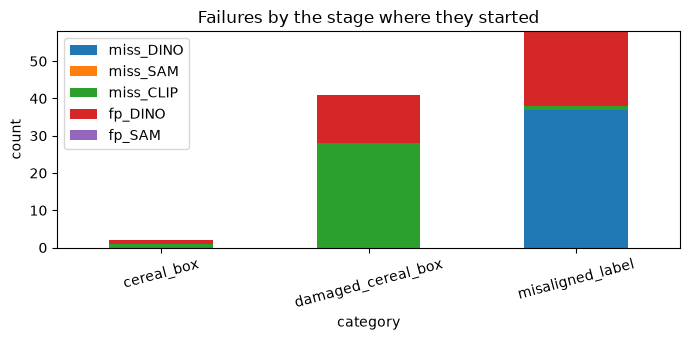

In [7]:
stages = read('stage_table.csv').set_index('category').loc[CATEGORIES]
display(stages)
ax = stages[['miss_DINO', 'miss_SAM', 'miss_CLIP', 'fp_DINO', 'fp_SAM']].plot.bar(stacked=True, figsize=(7, 3.5), rot=15)
ax.set_title(TAG + 'Failures by the stage where they started'); ax.set_ylabel('count'); plt.tight_layout(); plt.show()

## 6. Slices
Image conditions, and recall for damaged boxes on subtle versus clear dents.

,slice,category,precision,recall,f1,n_truth,n_images
0,condition clean,cereal_box,1.0000,1.0000,1.0000,33,10.0
1,condition typical,cereal_box,1.0000,1.0000,1.0000,31,10.0
2,condition hard,cereal_box,0.9697,0.9697,0.9697,33,10.0
3,condition clean,damaged_cereal_box,0.4286,0.1875,0.2609,16,10.0
4,condition typical,damaged_cereal_box,0.3750,0.3333,0.3529,9,10.0
5,condition hard,damaged_cereal_box,0.5556,0.3571,0.4348,14,10.0
6,condition clean,misaligned_label,0.0000,0.0000,0.0000,12,10.0
7,condition typical,misaligned_label,0.0000,0.0000,0.0000,16,10.0
8,condition hard,misaligned_label,0.0000,0.0000,0.0000,10,10.0


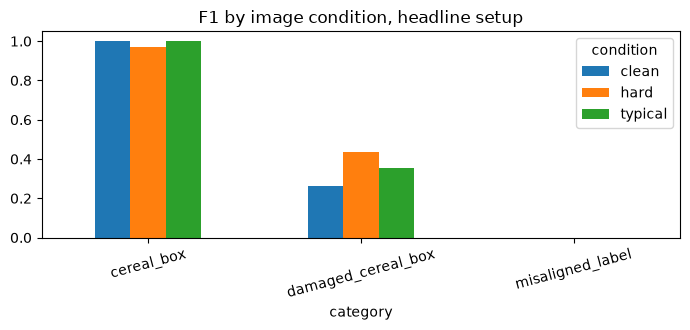

,slice,verifier,recall,recall_lo,recall_hi,n_truth,groups
9,dent severity clear,off,1.0000,0.8754,1.0000,27,3.0
10,dent severity subtle,off,1.0000,0.7575,1.0000,12,1.0
11,dent severity clear,on,0.0741,0.0206,0.2337,27,3.0
12,dent severity subtle,on,0.7500,0.4677,0.9111,12,1.0


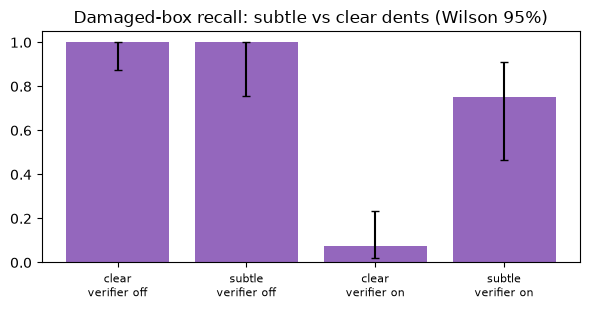

In [8]:
slices = read('slices.csv')
cond = slices[slices.slice.str.startswith('condition')]
display(cond[['slice', 'category', 'precision', 'recall', 'f1', 'n_truth', 'n_images']])
table = cond.assign(condition=cond.slice.str.replace('condition ', '')).pivot(index='category', columns='condition', values='f1').loc[CATEGORIES]
ax = table.plot.bar(figsize=(7, 3.4), rot=15); ax.set_ylim(0, 1.05); ax.set_title(TAG + 'F1 by image condition, headline setup'); plt.tight_layout(); plt.show()
dents = slices[slices.slice.str.startswith('dent severity')]
display(dents[['slice', 'verifier', 'recall', 'recall_lo', 'recall_hi', 'n_truth', 'groups']])
fig, ax = plt.subplots(figsize=(6, 3.2))
names = dents.slice.str.replace('dent severity ', '') + '\nverifier ' + dents.verifier
ax.bar(names, dents.recall, yerr=[dents.recall - dents.recall_lo, dents.recall_hi - dents.recall], capsize=3, color='tab:purple')
ax.set_ylim(0, 1.05); ax.set_title(TAG + 'Damaged-box recall: subtle vs clear dents (Wilson 95%)'); ax.tick_params(axis='x', labelsize=8)
plt.tight_layout(); plt.show()

## 7. Calibration
Expected calibration error with 10 fixed equal-width bins. A raw CLIP cosine is not a probability; the verifier's confidence is a softmax over the contrast phrases at the frozen temperature.

,ECE
temperature,
raw Grounding DINO score (information only),0.1105
verifier at the frozen temperature,0.0921


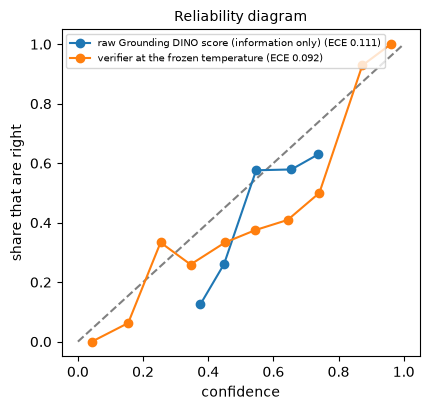

,empty


In [9]:
cal = read('calibration.csv')
display(cal.groupby('temperature').ece.first().to_frame('ECE'))
fig, ax = plt.subplots(figsize=(4.4, 4.2))
ax.plot([0, 1], [0, 1], linestyle='--', color='gray')
for name, rows in cal[cal['count'] > 0].groupby('temperature'):
    ax.plot(rows.mean_conf, rows.accuracy, marker='o', label=f'{name} (ECE {rows.ece.iloc[0]:.3f})')
ax.set_xlabel('confidence'); ax.set_ylabel('share that are right'); ax.legend(fontsize=7)
ax.set_title(TAG + 'Reliability diagram', fontsize=10); plt.tight_layout(); plt.show()
display(read('ties.csv'))

## Limitations
- Val and showcase numbers are not test numbers. The choices were made on val, so val is optimistic.
- Boxes and backgrounds repeat across images, so instances are not independent and the intervals understate the real uncertainty. Every table carries the number of distinct product groups for that reason.
- See `docs/make_synth_spec.md` for the full list: what "held out" means here, printed text on the boxes, simulated dents, the unlabelled shipping sticker on the cardboard distractor, and products placed in front of the furniture.